<a href="https://colab.research.google.com/github/Edubel77/enrutaia/blob/main/notebooks/D4_limpieza_baseline_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Día 4 · Limpieza, baseline y CNN
- **Parte A · Proyecto EnrutaIA:** reglas de limpieza (`src/limpieza.py`), pruebas `pytest`, splits limpios y baseline E0.
- **Parte B · Lab 1.4:** CNN frente a MLP en Fashion-MNIST, evaluación en test y análisis de errores.

In [1]:
!mkdir -p src tests

In [2]:
%%writefile src/limpieza.py
"""Reglas de limpieza de EnrutaIA (decididas en el EDA del Día 3)."""
import pandas as pd


def normalizar(texto: str) -> str:
    """Minúsculas, sin espacios en los extremos y espacios internos reducidos a uno."""
    return " ".join(str(texto).lower().split())


def eliminar_conflictos(df: pd.DataFrame, col_texto="text", col_etiqueta="dominio") -> pd.DataFrame:
    """Regla 2: elimina TODAS las apariciones de un texto que tenga más de una etiqueta."""
    norm = df[col_texto].map(normalizar)
    n_etiquetas = df.groupby(norm)[col_etiqueta].transform("nunique")
    return df[n_etiquetas == 1].reset_index(drop=True)


def deduplicar(df: pd.DataFrame, col_texto="text") -> pd.DataFrame:
    """Regla 3: quita duplicados dentro de un split, conservando la primera aparición."""
    norm = df[col_texto].map(normalizar)
    return df[~norm.duplicated(keep="first")].reset_index(drop=True)


def quitar_presentes_en(df: pd.DataFrame, referencia: pd.DataFrame, col_texto="text") -> pd.DataFrame:
    """Reglas 4 y 5: quita de df los textos que ya aparecen en referencia."""
    vistos = set(referencia[col_texto].map(normalizar))
    return df[~df[col_texto].map(normalizar).isin(vistos)].reset_index(drop=True)


def limpiar_splits(train, val, test, col_texto="text", col_etiqueta="dominio"):
    """Aplica las 5 reglas en orden y devuelve (train, val, test) limpios."""
    # Regla 2: conflictos, mirando el dataset COMPLETO
    todo = pd.concat([train.assign(_split="train"),
                      val.assign(_split="validation"),
                      test.assign(_split="test")], ignore_index=True)
    todo = eliminar_conflictos(todo, col_texto, col_etiqueta)
    train, val, test = (todo[todo["_split"] == s].drop(columns="_split")
                        for s in ["train", "validation", "test"])
    # Regla 3: duplicados dentro de cada split
    train, val, test = (deduplicar(d, col_texto) for d in (train, val, test))
    # Regla 4: validación y test sin textos de train
    val = quitar_presentes_en(val, train, col_texto)
    test = quitar_presentes_en(test, train, col_texto)
    # Regla 5: test sin textos de validación
    test = quitar_presentes_en(test, val, col_texto)
    return train.reset_index(drop=True), val, test

Writing src/limpieza.py


In [3]:
import sys
sys.path.append(".")            # para que Python encuentre la carpeta src/
from src.limpieza import normalizar
print(normalizar("  Pon   MÚSICA de Shakira  "))

pon música de shakira


In [4]:
%%writefile tests/test_limpieza.py
import pandas as pd
from src.limpieza import (normalizar, eliminar_conflictos, deduplicar,
                          quitar_presentes_en, limpiar_splits)


def df(textos, dominios=None):
    """Ayudante: crea un DataFrame pequeño para las pruebas."""
    return pd.DataFrame({"text": textos, "dominio": dominios or ["x"] * len(textos)})


def test_normalizar_minusculas_y_espacios():
    assert normalizar("  Pon   MÚSICA  ") == "pon música"


def test_normalizar_acepta_valores_no_texto():
    assert normalizar(123) == "123"


def test_deduplicar_conserva_la_primera_aparicion():
    entrada = df(["Hola", "hola ", "adiós", "HOLA"], ["a", "b", "c", "d"])
    salida = deduplicar(entrada)
    assert list(salida["text"]) == ["Hola", "adiós"]
    assert list(salida["dominio"]) == ["a", "c"]


def test_eliminar_conflictos_quita_todas_las_apariciones():
    entrada = df(["borrar", "Borrar", "pon música"], ["calendar", "lists", "audio"])
    salida = eliminar_conflictos(entrada)
    assert list(salida["text"]) == ["pon música"]


def test_eliminar_conflictos_conserva_duplicados_con_la_misma_etiqueta():
    entrada = df(["hola", "Hola"], ["general", "general"])
    assert len(eliminar_conflictos(entrada)) == 2


def test_quitar_presentes_en():
    val = df(["pon música", "qué hora es"])
    train = df(["Pon Música"])
    assert list(quitar_presentes_en(val, train)["text"]) == ["qué hora es"]


def test_limpiar_splits_no_deja_fugas():
    train = df(["a", "b", "b", "c"])
    val = df(["c", "d"])
    test = df(["a", "d", "e"])
    tr, va, te = limpiar_splits(train, val, test)
    n = lambda d: set(d["text"].map(normalizar))
    assert n(tr) & n(va) == set()
    assert n(tr) & n(te) == set()
    assert n(va) & n(te) == set()
    assert list(te["text"]) == ["e"]


def test_limpiar_splits_no_modifica_los_datos_originales():
    train = df(["a", "a"])
    limpiar_splits(train, df(["b"]), df(["c"]))
    assert len(train) == 2



def test_regla5_quita_de_test_lo_que_esta_en_validacion():
    train = df(["enciende la luz"])
    val   = df(["qué hora es"])
    test  = df(["qué hora es", "pon música"])
    tr, va, te = limpiar_splits(train, val, test)
    assert "qué hora es" not in list(te["text"])
    assert "pon música" in list(te["text"])
    assert "qué hora es" in list(va["text"])

Writing tests/test_limpieza.py


In [5]:
!python -m pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 9 items                                                              

tests/test_limpieza.py::test_normalizar_minusculas_y_espacios PASSED     [ 11%]
tests/test_limpieza.py::test_normalizar_acepta_valores_no_texto PASSED   [ 22%]
tests/test_limpieza.py::test_deduplicar_conserva_la_primera_aparicion PASSED [ 33%]
tests/test_limpieza.py::test_eliminar_conflictos_quita_todas_las_apariciones PASSED [ 44%]
tests/test_limpieza.py::test_eliminar_conflictos_conserva_duplicados_con_la_misma_etiqueta PASSED [ 55%]
tests/test_limpieza.py::test_quitar_presentes_en PASSED                  [ 66%]
tests/test_limpieza.py::test_limpiar_splits_no_deja_fugas PASSED         [ 77%]
tests/test_limpieza.py::test_limpiar

In [6]:
!python -m pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 9 items                                                              

tests/test_limpieza.py::test_normalizar_minusculas_y_espacios PASSED     [ 11%]
tests/test_limpieza.py::test_normalizar_acepta_valores_no_texto PASSED   [ 22%]
tests/test_limpieza.py::test_deduplicar_conserva_la_primera_aparicion PASSED [ 33%]
tests/test_limpieza.py::test_eliminar_conflictos_quita_todas_las_apariciones PASSED [ 44%]
tests/test_limpieza.py::test_eliminar_conflictos_conserva_duplicados_con_la_misma_etiqueta PASSED [ 55%]
tests/test_limpieza.py::test_quitar_presentes_en PASSED                  [ 66%]
tests/test_limpieza.py::test_limpiar_splits_no_deja_fugas PASSED         [ 77%]
tests/test_limpieza.py::test_limpiar

In [7]:
!python -m pytest tests/ -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0, platformdirs-4.14.3
collected 9 items                                                              

tests/test_limpieza.py::test_normalizar_minusculas_y_espacios PASSED     [ 11%]
tests/test_limpieza.py::test_normalizar_acepta_valores_no_texto PASSED   [ 22%]
tests/test_limpieza.py::test_deduplicar_conserva_la_primera_aparicion PASSED [ 33%]
tests/test_limpieza.py::test_eliminar_conflictos_quita_todas_las_apariciones PASSED [ 44%]
tests/test_limpieza.py::test_eliminar_conflictos_conserva_duplicados_con_la_misma_etiqueta PASSED [ 55%]
tests/test_limpieza.py::test_quitar_presentes_en PASSED                  [ 66%]
tests/test_limpieza.py::test_limpiar_splits_no_deja_fugas PASSED         [ 77%]
tests/test_limpieza.py::test_limpiar

In [8]:
# Paso 3: aplicar la limpieza a MASSIVE y guardar los splits limpios
import hashlib
import pandas as pd
from datasets import load_dataset
from src.limpieza import limpiar_splits, normalizar

ds = load_dataset("mteb/amazon_massive_intent", "es")

def preparar(split):
    d = ds[split].to_pandas()[["text", "label"]]
    d["dominio"] = d["label"].str.split("_").str[0]
    return d

train0, val0, test0 = (preparar(s) for s in ["train", "validation", "test"])
train, val, test = limpiar_splits(train0, val0, test0)

# 1) Resumen de la limpieza
resumen = pd.DataFrame({"original": [len(train0), len(val0), len(test0)],
                        "limpio":   [len(train),  len(val),  len(test)]},
                       index=["train", "validation", "test"])
resumen["eliminados"] = resumen["original"] - resumen["limpio"]
resumen["% eliminado"] = (resumen["eliminados"] / resumen["original"] * 100).round(1)
print(resumen.to_string())

# 2) Verificaciones sobre los datos REALES (no solo en las pruebas)
n = lambda d: set(d["text"].map(normalizar))
print("\nFugas train-val :", len(n(train) & n(val)))
print("Fugas train-test:", len(n(train) & n(test)))
print("Fugas val-test  :", len(n(val) & n(test)))
print("Dominios por split:", {s: d["dominio"].nunique() for s, d in
                              [("train", train), ("validation", val), ("test", test)]})
print("Mínimo de ejemplos por dominio:", {s: int(d["dominio"].value_counts().min()) for s, d in
                                          [("train", train), ("validation", val), ("test", test)]})

# 3) Guardar y calcular una huella (hash) de cada archivo
!mkdir -p data/limpio
for nombre, d in [("train", train), ("validation", val), ("test", test)]:
    ruta = f"data/limpio/{nombre}.csv"
    d.to_csv(ruta, index=False)
    huella = hashlib.md5(open(ruta, "rb").read()).hexdigest()
    print(f"{ruta}: {len(d)} filas | md5 = {huella}")

README.md:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

train/es.json.gz: reconstructing file:   0%|          |  0.00B /  204kB            

train/es.json.gz: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

            original  limpio  eliminados  % eliminado
train          11514   11158         356          3.1
validation      2033    1915         118          5.8
test            2974    2806         168          5.6

Fugas train-val : 0
Fugas train-test: 0
Fugas val-test  : 0
Dominios por split: {'train': 18, 'validation': 18, 'test': 18}
Mínimo de ejemplos por dominio: {'train': 211, 'validation': 26, 'test': 49}
data/limpio/train.csv: 11158 filas | md5 = cc0ff7796f8e1d1df56862a9f708d521
data/limpio/validation.csv: 1915 filas | md5 = ba68845308293612e717aa7c1a55887c
data/limpio/test.csv: 2806 filas | md5 = 4aa30d7940052535f5646e420cf8cd48


In [9]:
# Paso 4: baseline E0 - TF-IDF + regresión logística
import json, time, sklearn
import numpy as np
from sklearn.pipeline import make_pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report

e0 = make_pipeline(
    FeatureUnion([
        ("palabras",   TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ]),
    LogisticRegression(max_iter=2000),
)

inicio = time.time()
e0.fit(train["text"], train["dominio"])          # SOLO train
segundos = time.time() - inicio

pred_val = e0.predict(val["text"])                # evaluar en VALIDACIÓN (el test no se toca)
macro_f1 = f1_score(val["dominio"], pred_val, average="macro")
exactitud = accuracy_score(val["dominio"], pred_val)

print(f"E0 · validación -> macro-F1: {macro_f1:.4f} | exactitud: {exactitud:.4f} | entrenamiento: {segundos:.1f} s")
print("\nReporte por dominio (validación):")
print(classification_report(val["dominio"], pred_val, digits=3))

# Guardar el resultado en un archivo (las métricas salen del código, no se copian a mano)
!mkdir -p results
resultado = {
    "experimento": "E0",
    "modelo": "TF-IDF (palabras 1-2 + caracteres 2-5) + LogisticRegression",
    "datos": "data/limpio (splits limpios)",
    "split_evaluado": "validation",
    "macro_f1": round(macro_f1, 4),
    "accuracy": round(exactitud, 4),
    "segundos_entrenamiento": round(segundos, 1),
    "sklearn": sklearn.__version__,
}
with open("results/E0_tfidf.json", "w") as f:
    json.dump(resultado, f, indent=2, ensure_ascii=False)
print("Guardado en results/E0_tfidf.json")

E0 · validación -> macro-F1: 0.8725 | exactitud: 0.8789 | entrenamiento: 16.2 s

Reporte por dominio (validación):
                precision    recall  f1-score   support

         alarm      1.000     0.885     0.939        61
         audio      0.917     0.846     0.880        26
      calendar      0.901     0.952     0.926       269
       cooking      0.971     0.810     0.883        42
      datetime      0.926     0.833     0.877        60
         email      0.967     0.942     0.955       156
       general      0.650     0.565     0.605       115
           iot      0.969     0.931     0.949       101
         lists      0.915     0.915     0.915       106
         music      0.951     0.736     0.830        53
          news      0.859     0.827     0.843        81
          play      0.913     0.951     0.931       243
            qa      0.702     0.923     0.798       209
recommendation      0.825     0.701     0.758        67
        social      0.931     0.818     0.87

## Parte B · Lab 1.4: CNN frente a MLP (Fashion-MNIST)

In [10]:
# Lab 1.4 - CNN vs MLP en Fashion-MNIST
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

print("GPU:", tf.config.list_physical_devices("GPU"))
tf.keras.utils.set_random_seed(42)

(X_full, y_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
X_full = (X_full.astype("float32") / 255.0)[..., np.newaxis]   # (n, 28, 28, 1): 1 canal (gris)
X_test = (X_test.astype("float32") / 255.0)[..., np.newaxis]
idx = np.random.default_rng(42).permutation(len(X_full))       # mismo split que el Día 3
X_val, y_val = X_full[idx[:10_000]], y_full[idx[:10_000]]
X_train, y_train = X_full[idx[10_000:]], y_full[idx[10_000:]]
nombres = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"]

def nuevo_early_stopping():
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

def crear_mlp():
    tf.keras.utils.set_random_seed(42)
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation="softmax"),
    ], name="MLP")

def crear_cnn():
    tf.keras.utils.set_random_seed(42)
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.layers.Conv2D(32, 3, activation="relu", padding="same"),   # 32 filtros de 3x3
        keras.layers.MaxPooling2D(),                                     # 28x28 -> 14x14
        keras.layers.Conv2D(64, 3, activation="relu", padding="same"),   # 64 filtros de 3x3
        keras.layers.MaxPooling2D(),                                     # 14x14 -> 7x7
        keras.layers.Flatten(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation="softmax"),
    ], name="CNN")

resultados = {}
for crear in (crear_mlp, crear_cnn):
    m = crear()
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = time.time()
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30,
              batch_size=64, verbose=0, callbacks=[nuevo_early_stopping()])
    seg = time.time() - inicio
    val_loss, val_acc = m.evaluate(X_val, y_val, verbose=0)
    epocas = len(h.history["loss"])
    resultados[m.name] = (m, h)
    print(f"{m.name:<4} | parámetros: {m.count_params():>8,} | épocas: {epocas:>2} | "
          f"seg/época: {seg / epocas:5.1f} | val acc: {val_acc:.4f} | val loss: {val_loss:.4f}")

resultados["CNN"][0].summary()

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MLP  | parámetros:  101,770 | épocas: 14 | seg/época:   2.8 | val acc: 0.8862 | val loss: 0.3047
CNN  | parámetros:   50,186 | épocas: 16 | seg/época:   4.0 | val acc: 0.9184 | val loss: 0.2272


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        31,370 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 150,560 (588.13 KB)

 Trainable params: 50,186 (196.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 100,374 (392.09 KB)

### Conclusión del Lab 1.4
- La CNN (50.186 parámetros) superó al MLP (101.770) en validación: 0,9186 frente a 0,8886, con la mitad de parámetros.
- **Test (evaluado una sola vez):** exactitud 0,9131, frente a 0,9186 en validación (diferencia de 0,0055). La validación fue una buena estimación del desempeño con datos nuevos.
- Confusión principal: Camisa ↔ Camiseta (127 y 73 casos) y Camisa → Abrigo (61). "Camisa" es la clase más difícil por no tener rasgos exclusivos a 28×28 en gris.
- Alta confianza no es acierto: hubo errores con ~100 % de seguridad (p. ej. Botín → Sandalia).

CNN · TEST -> exactitud: 0.9129 | pérdida: 0.2447


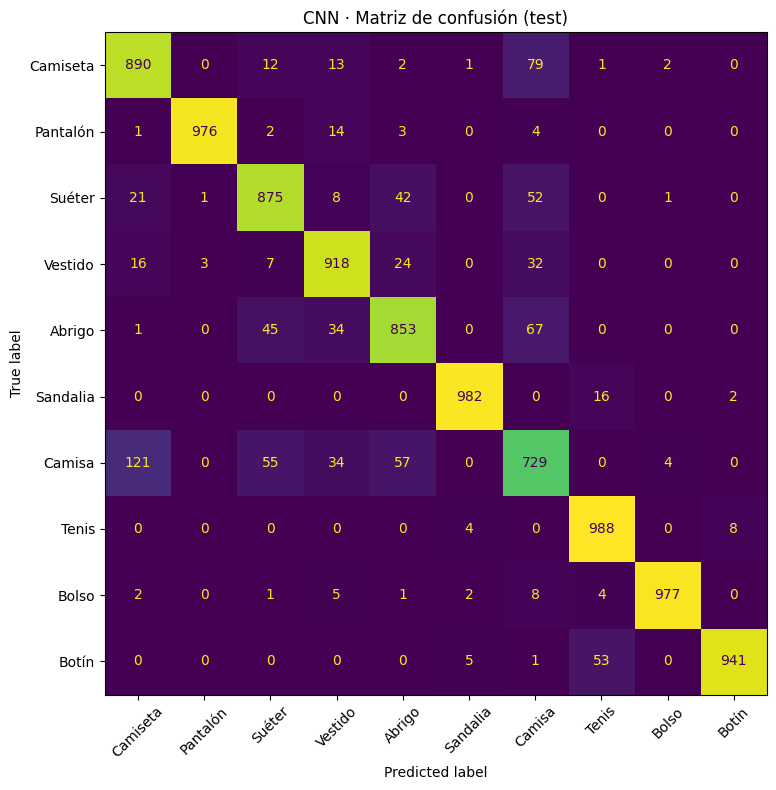


Confusiones más frecuentes (real -> predicho):
  Camisa    -> Camiseta : 121 veces
  Camiseta  -> Camisa   : 79 veces
  Abrigo    -> Camisa   : 67 veces


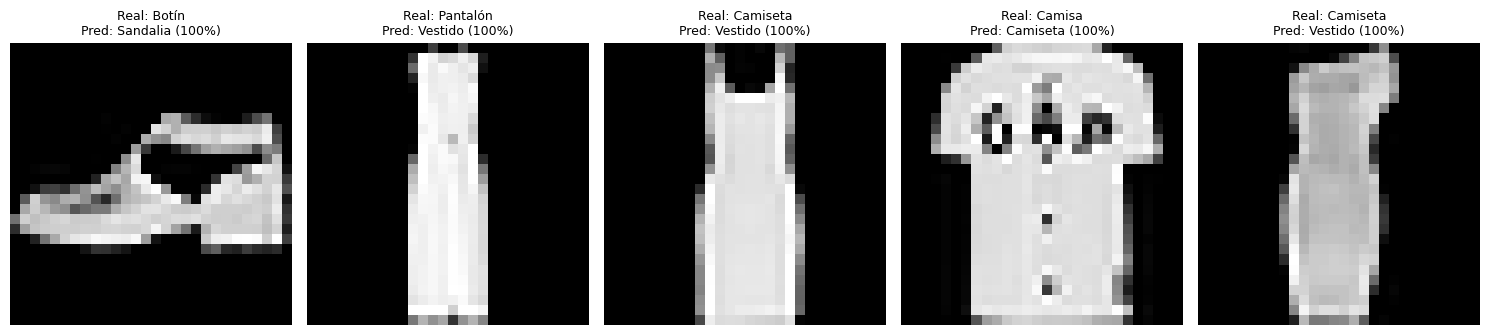

In [11]:
# Lab 1.4 - Paso 5b: evaluación final en test (una sola vez) y errores
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cnn = resultados["CNN"][0]
test_loss, test_acc = cnn.evaluate(X_test, y_test, verbose=0)
print(f"CNN · TEST -> exactitud: {test_acc:.4f} | pérdida: {test_loss:.4f}")

probs = cnn.predict(X_test, verbose=0)
pred = probs.argmax(axis=1)

# Matriz de confusión
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=nombres).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("CNN · Matriz de confusión (test)"); plt.tight_layout(); plt.show()

# Los 3 pares de clases que más se confunden
cm_sin_diag = cm.copy(); np.fill_diagonal(cm_sin_diag, 0)
pares = np.dstack(np.unravel_index(np.argsort(cm_sin_diag.ravel())[::-1][:3], cm.shape))[0]
print("\nConfusiones más frecuentes (real -> predicho):")
for r, p in pares:
    print(f"  {nombres[r]:<9} -> {nombres[p]:<9}: {cm[r, p]} veces")

# 5 errores en los que el modelo estaba MÁS seguro
errores = np.where(pred != y_test)[0]
peores = errores[np.argsort(probs[errores].max(axis=1))[::-1][:5]]
fig, ax = plt.subplots(1, 5, figsize=(15, 3.5))
for a, i in zip(ax, peores):
    a.imshow(X_test[i].squeeze(), cmap="gray"); a.axis("off")
    a.set_title(f"Real: {nombres[y_test[i]]}\nPred: {nombres[pred[i]]} ({probs[i].max():.0%})", fontsize=9)
plt.tight_layout(); plt.show()

In [12]:
import sklearn, datasets, pytest, pandas
print(f"scikit-learn=={sklearn.__version__}\ndatasets=={datasets.__version__}\npytest=={pytest.__version__}")

scikit-learn==1.6.1
datasets==4.8.5
pytest==8.4.2


In [13]:
!zip -r archivos_dia4.zip src tests data results -x "*__pycache__*" "*.pytest_cache*"

  adding: src/ (stored 0%)
  adding: src/limpieza.py (deflated 63%)
  adding: tests/ (stored 0%)
  adding: tests/test_limpieza.py (deflated 65%)
  adding: data/ (stored 0%)
  adding: data/limpio/ (stored 0%)
  adding: data/limpio/validation.csv (deflated 75%)
  adding: data/limpio/test.csv (deflated 76%)
  adding: data/limpio/train.csv (deflated 79%)
  adding: results/ (stored 0%)
  adding: results/E0_tfidf.json (deflated 29%)


In [14]:
test_loss, test_acc = cnn.evaluate(X_test, y_test, verbose=0)
print(f"CNN · TEST -> exactitud: {test_acc:.4f} | pérdida: {test_loss:.4f}")

CNN · TEST -> exactitud: 0.9129 | pérdida: 0.2447


La exactitud en test fue 0,9131, frente a 0,9186 en validación (diferencia de 0,0055). Esto indica que la validación fue una buena estimación del desempeño con datos nuevos y que la decisión de elegir la CNN se sostiene.